# ITM 454 - Natural Language Processing
## Final Project: Sentiment Analysis of Khmer Customer Reviews — **03. Neural Network: BiLSTM**

---

TF-IDF (notebook 02) treats a review as a **bag of words**: word order and context are lost, so
*"thank you, even though the bus was late"* looked positive.

Now we use a **neural network that reads the words in order**: a **bidirectional LSTM**, with the same **4 steps** as in class:

1. **Data** → `DataLoader`
2. **NN Model** → `class BiLSTMClassifier(nn.Module)`
3. **Loss & Optimizer** → `CrossEntropyLoss` (with class weights) + `Adam`
4. **Training loop** → predict → loss → `zero_grad` → `backward` → `step`, for 15 epochs

The words start with **pretrained fastText Khmer vectors** (like GloVe in the professor's notebook, but for Khmer).

### 0. Setup

**How to run:** open this notebook from the `notebooks/` folder of the project and run all cells (Kernel → Restart & Run All).
The setup cell below goes to the project folder and installs the packages from `requirements.txt`
(see the README for creating the Python environment). All paths in this notebook are relative to the project folder.

**Before this notebook:** Run **notebook 01** first (its outputs are already in the repository). A GPU makes training faster but is not required.

| Input file | Created by |
|---|---|
| `data/processed/*.csv`, `data/processed/settings.json` | notebook 01 |
| `src/preprocess.py` | notebook 01 |
| `models/cc.km.300.vec.gz` (fastText Khmer vectors, 145 MB) | downloaded automatically by this notebook on its first run (not in the repository: too large) |


| Output | Used by |
|---|---|
| `results/metrics/bilstm.json`, `results/predictions/bilstm_*.csv` | notebook 05 |
| `results/figures/03_*.png` | report |

In [ ]:
import os

# 1. Go to the project folder (this notebook is in its notebooks/ folder)
PROJECT_DIR = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
os.chdir(PROJECT_DIR)

# 2. Install the packages (the exact versions we used are in requirements.txt)
%pip install -q -r requirements.txt

# 3. Folders for the outputs
for folder in ["data/processed", "results/predictions", "results/metrics", "results/figures", "models", "src"]:
    os.makedirs(folder, exist_ok=True)
print("Project folder:", os.path.basename(os.path.abspath(".")))

### 1. Import Required Libraries

In [2]:
import os
import sys
import gzip
import json
import time
import copy
import random
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score, accuracy_score

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from datasets import Dataset, disable_progress_bars
disable_progress_bars()   # no progress bar for every .map()

# Seed values for reproducibility
SEED = 45
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True   # same results every run on the same GPU
torch.backends.cudnn.benchmark = False

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, f"({torch.cuda.get_device_name(0)})" if device == "cuda" else "")

Device: cuda (NVIDIA GeForce RTX 4060 Laptop GPU)


#### Khmer font for plots

The default matplotlib font has no Khmer letters, so Khmer text would appear as empty boxes □□□.
We use a Khmer font if one is installed (Noto Sans Khmer, Khmer OS or Khmer UI).

In [4]:
from matplotlib import font_manager

installed_fonts = {font.name for font in font_manager.fontManager.ttflist}
khmer_font = next((name for name in ["Noto Sans Khmer", "Khmer OS", "Khmer UI", "DaunPenh"] if name in installed_fonts), None)
if khmer_font:
    plt.rcParams["font.family"] = [khmer_font, "DejaVu Sans"]   # Khmer font first, normal font as backup
print("Khmer font for plots:", khmer_font or "none found (Khmer text may appear as boxes)")

Khmer font for plots: Khmer OS


### 2. Dataset

The same splits as notebook 02 (saved by notebook 01).

In [5]:
with open("data/processed/settings.json") as f:
    settings = json.load(f)
label_names = settings["label_names"]      # ["negative", "positive"]
max_len = settings["max_len"]              # chosen in notebook 01 (95th percentile of review length)

train = pd.read_csv("data/processed/train.csv")
val = pd.read_csv("data/processed/val.csv")
test_translated = pd.read_csv("data/processed/test_translated.csv")
test_native = pd.read_csv("data/processed/test_native.csv")

for name, data in [("train", train), ("val", val), ("test_translated", test_translated), ("test_native", test_native)]:
    print(f"{name:16s}: {len(data):5d} reviews")
print("max_len:", max_len)

LABEL_SOURCE = settings["test_native_label_source"]
if LABEL_SOURCE == "silver":
    print("\n⚠ test_native uses SILVER (AI) labels → its results are PROVISIONAL.")

train           :  2858 reviews
val             :   357 reviews
test_translated :   358 reviews
test_native     :   214 reviews
max_len: 47


### 3. Data (Text) Preprocessing

Already done in notebook 01 (`preprocess_text`: normalization, punctuation removal, khmer-nltk word segmentation,
**negation words kept**). We turn the saved string back into a list of words.

In [6]:
sys.path.insert(0, os.getcwd())
from src.preprocess import preprocess_text   # same function as notebook 01 (used for new reviews)

for data in [train, val, test_translated, test_native]:
    data["token_list"] = data["tokens"].str.split()

print("text_km:", train["text_km"].iloc[0])
print("tokens :", train["token_list"].iloc[0])

text_km: គេហទំព័រត្រូវធ្វើបច្ចុប្បន្នភាព។ កន្លែងឡើងឡានបានផ្លាស់ទីហើយ។ ឡានស្អាត ប៉ុន្តែកៅអីខូច។
tokens : ['គេហទំព័រ', 'ត្រូវ', 'ធ្វើ', 'បច្ចុប្បន្នភាព', 'កន្លែង', 'ឡើង', 'ឡាន', 'បាន', 'ផ្លាស់ទី', 'ហើយ', 'ឡាន', 'ស្អាត', 'ប៉ុន្តែ', 'កៅអី', 'ខូច']


### 4. Build the Vocabulary

Each unique word gets an ID, like in the professor's notebook:

- only the **training set** (the model must not see the test data)
- words that appear **at least 2 times**
- 2 special words: `<pad>` (ID 0) fills short reviews up to `max_len`, `<unk>` (ID 1) = any unknown word

In [7]:
word_counts = Counter(word for tokens in train["token_list"] for word in tokens)

vocab = ["<pad>", "<unk>"] + [word for word, count in word_counts.items() if count >= 2]
word2idx = {word: i for i, word in enumerate(vocab)}
idx2word = {i: word for i, word in enumerate(vocab)}
vocab_size = len(vocab)

print(f"Unique words in train : {len(word_counts)}")
print(f"Vocabulary size       : {vocab_size}")
print(f"Most common words     : {word_counts.most_common(10)}")

Unique words in train : 2329
Vocabulary size       : 1507
Most common words     : [('មិន', 1589), ('ល្អ', 1535), ('ខ្ញុំ', 1357), ('និង', 1332), ('មាន', 1306), ('ហើយ', 1126), ('យើង', 1094), ('ម៉ោង', 1052), ('អ្នកបើកបរ', 1030), ('ឡាន', 870)]


### 5. Pre-trained Word Embeddings (fastText Khmer)

Instead of GloVe (English), we use **fastText** vectors for **Khmer** (Grave et al., 2018), trained on Khmer web pages
(Common Crawl). Each word = **300 numbers**, and similar words have similar vectors.

The file `cc.km.300.vec.gz` (145 MB) is downloaded once into `models/`. We read it line by line and keep only the
words of our vocabulary.

In [8]:
FASTTEXT_URL = "https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.km.300.vec.gz"
FASTTEXT_FILE = "models/cc.km.300.vec.gz"
embedding_size = 300

if not os.path.exists(FASTTEXT_FILE):
    try:
        print("Downloading fastText Khmer vectors (145 MB, only once)...")
        urllib.request.urlretrieve(FASTTEXT_URL, FASTTEXT_FILE)
    except Exception as error:
        print("Download failed:", error)

def load_fasttext(path, word2idx):
    """Returns {word: vector} for the words of our vocabulary that are in the fastText file."""
    vectors = {}
    with gzip.open(path, "rt", encoding="utf-8") as f:
        next(f)                                    # first line: number of words and size
        for line in f:
            word, rest = line.rstrip().split(" ", 1)
            if word in word2idx:
                vectors[word] = np.array(rest.split(" "), dtype=np.float32)
    return vectors

USE_FASTTEXT = os.path.exists(FASTTEXT_FILE)
fasttext = load_fasttext(FASTTEXT_FILE, word2idx) if USE_FASTTEXT else {}
print("fastText vectors loaded:", USE_FASTTEXT, "| words found:", len(fasttext))

fastText vectors loaded: True | words found: 1335


Similar words already have similar vectors (cosine similarity, 1 = same direction):

In [9]:
def similarity(word1, word2):
    v1, v2 = fasttext[word1], fasttext[word2]
    return float(v1 @ v2 / (np.linalg.norm(v1) * np.linalg.norm(v2)))

word_pairs = [("ល្អ", "អស្ចារ្យ"),     # good vs. amazing
              ("ល្អ", "អាក្រក់"),      # good vs. bad
              ("ឡាន", "រថយន្ត"),       # car vs. vehicle
              ("យឺត", "ពន្យារ"),        # late vs. delay
              ("ឡាន", "ពេញចិត្ត")]     # car vs. satisfied (unrelated)
for word1, word2 in word_pairs:
    if word1 in fasttext and word2 in fasttext:
        print(f"{word1:8s} vs {word2:9s}: {similarity(word1, word2):.3f}")

ល្អ      vs អស្ចារ្យ : 0.384
ល្អ      vs អាក្រក់  : 0.551
ឡាន      vs រថយន្ត   : 0.477
យឺត      vs ពន្យារ   : 0.204
ឡាន      vs ពេញចិត្ត : 0.056


#### The embedding matrix

One row per word in our vocabulary (like the professor's GloVe matrix):
- word found in fastText → copy its vector
- not found (and `<pad>`, `<unk>`) → 300 zeros (learned during training, because we **fine-tune** the embeddings)

In [10]:
embedding_matrix = np.zeros((vocab_size, embedding_size), dtype=np.float32)

if USE_FASTTEXT:
    found = 0
    for word, idx in word2idx.items():
        if word in fasttext:
            embedding_matrix[idx] = fasttext[word]
            found += 1
    print(f"Embedding matrix shape: {embedding_matrix.shape}  ({vocab_size} words x {embedding_size} numbers)")
    print(f"Words found in fastText: {found} ({found / vocab_size:.1%})")
    missing = [word for word in vocab[2:] if word not in fasttext]
    print("Some words not found:", missing[:10])
else:
    # Fallback: random start vectors (the model then learns all word vectors from our data only)
    embedding_matrix = np.random.normal(0, 0.1, (vocab_size, embedding_size)).astype(np.float32)
    embedding_matrix[0] = 0
    print("⚠ fastText NOT available → randomly initialized embeddings are used.")

Embedding matrix shape: (1507, 300)  (1507 words x 300 numbers)
Words found in fastText: 1335 (88.6%)
Some words not found: ['champa', 'buva', 'ធ្វើឱ្យ', 'toyota', 'hiace', 'ford', 'larryta', 'បើកក់', 'seila', 'pipay']


### 6. Create the Training Data (DataLoader)

#### Words → IDs

Every review becomes exactly `max_len` word IDs: unknown words → 1 (`<unk>`), too long → cut, too short → `<pad>` (0) at the end.
We build a Hugging Face `Dataset`, add the IDs with `.map()`, and use `with_format("torch")` so the `DataLoader` gives tensors.

In [11]:
def encode(example):
    ids = [word2idx.get(word, word2idx["<unk>"]) for word in example["tokens"].split()]
    ids = ids[:max_len]                                    # cut
    ids = ids + [word2idx["<pad>"]] * (max_len - len(ids))  # pad
    return {"input_ids": ids}

def to_dataset(data):
    dataset = Dataset.from_pandas(data[["tokens", "label_id"]].rename(columns={"label_id": "label"}), preserve_index=False)
    dataset = dataset.map(encode)
    return dataset.with_format("torch", columns=["input_ids", "label"])

train_data, val_data = to_dataset(train), to_dataset(val)
test_translated_data, test_native_data = to_dataset(test_translated), to_dataset(test_native)

print("Tokens   :", train["tokens"].iloc[0].split())
print("Input IDs:", train_data[0]["input_ids"].tolist())

Tokens   : ['គេហទំព័រ', 'ត្រូវ', 'ធ្វើ', 'បច្ចុប្បន្នភាព', 'កន្លែង', 'ឡើង', 'ឡាន', 'បាន', 'ផ្លាស់ទី', 'ហើយ', 'ឡាន', 'ស្អាត', 'ប៉ុន្តែ', 'កៅអី', 'ខូច']
Input IDs: [2, 3, 4, 5, 6, 7, 8, 9, 1, 10, 8, 11, 12, 13, 14, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


#### Batches

The DataLoader gives the model 32 reviews at a time. The training data is shuffled with a fixed seed, so every run is the same.

In [12]:
batch_size = 32
generator = torch.Generator().manual_seed(SEED)       # same shuffling every run
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, generator=generator)
val_loader = DataLoader(val_data, batch_size=batch_size)
test_translated_loader = DataLoader(test_translated_data, batch_size=batch_size)
test_native_loader = DataLoader(test_native_data, batch_size=batch_size)

print(f"Number of training batches: {len(train_loader)}")
batch = next(iter(train_loader))
print(f"input_ids shape: {batch['input_ids'].shape}  ({batch_size} reviews x {max_len} word IDs)")
print(f"label shape    : {batch['label'].shape}")

first = batch["input_ids"][0].tolist()
print("\nFirst review of the batch, decoded:", [idx2word[i] for i in first if i != 0])
print("Label:", label_names[batch["label"][0].item()])

Number of training batches: 90
input_ids shape: torch.Size([32, 47])  (32 reviews x 47 word IDs)
label shape    : torch.Size([32])

First review of the batch, decoded: ['គ្មាន', 'កន្លែង', 'ដាក់', 'ជើង', 'សោះ', 'ម៉ាស៊ីន', 'ត្រជាក់', 'គ្មាន', 'ប្រយោជន៍', 'អ្នកបើកបរ', 'មិន', 'ខ្វល់', 'ហើយ', 'មិន', 'អើពើ', 'យើង', 'ទាំងស្រុង', 'នឹង', 'មិន', 'ប្រើ', 'ក្រុមហ៊ុន', 'ឡានក្រុង', 'របស់', 'អ្នក', 'ម្តង', 'ទៀត', 'ឡើយ']
Label: negative


### 7. The Model (BiLSTM)

```
word IDs (max_len per review)                ← input layer
   ↓  word embedding (fastText, fine-tuned)      each word → 300 numbers          (batch, max_len, 300)
   ↓  BiLSTM, hidden 128 per direction           reads left→right AND right→left  (batch, max_len, 256)
   ↓  average the word vectors (ignore <pad>)    one review → 256 numbers         (batch, 256)
   ↓  hidden layer + ReLU + dropout 0.3          256 → 64 numbers
   ↓  output layer                               64 → 2 scores (negative, positive)
```

**LSTM** (Long Short-Term Memory): reads the review **one word at a time** and keeps a *memory* (a vector of 128 numbers)
that is updated after every word. So the vector of a word depends on **the words before it**.

**Bidirectional**: a second LSTM reads the review **backwards**. Each word now knows the words **before and after** it
(128 + 128 = 256 numbers per word).

Why this helps with Khmer **negation**: in **មិន** សូវ គោរព … **ទេ** ("not really respect … at all"), the negation is
split around the verb. The forward LSTM sees **មិន** before **គោរព** ("respect"), the backward LSTM sees **ទេ** after it.
A bag of words (TF-IDF) only sees that both words are *somewhere* in the review.

**Masked average**: we average only the real words, not the `<pad>` fillers (otherwise short reviews would be "diluted").

In [13]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, embedding_matrix, num_classes, hidden_size=128, dropout=0.3, freeze=False):
        super().__init__()
        # Word embedding: starts from fastText; freeze=False → the vectors are fine-tuned during training
        self.embedding = nn.Embedding.from_pretrained(torch.tensor(embedding_matrix), freeze=freeze, padding_idx=0)

        # Bidirectional LSTM: reads the review in both directions
        self.lstm = nn.LSTM(input_size=embedding_matrix.shape[1], hidden_size=hidden_size,
                            batch_first=True, bidirectional=True)

        self.hidden = nn.Linear(2 * hidden_size, 64)   # 256 → 64
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)               # randomly switches off 30% of the numbers while training
        self.output = nn.Linear(64, num_classes)         # 64 → 2 scores

    def forward(self, input_ids):
        x = self.embedding(input_ids)                    # (batch, max_len, 300)
        x, _ = self.lstm(x)                              # (batch, max_len, 256)

        # Masked average: only real words count, <pad> (ID 0) is ignored
        mask = (input_ids != 0).unsqueeze(-1).float()    # (batch, max_len, 1): 1 = real word, 0 = <pad>
        x = (x * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)   # (batch, 256)

        x = self.dropout(self.relu(self.hidden(x)))      # (batch, 64)
        return self.output(x)                            # (batch, 2)

torch.manual_seed(SEED)
model = BiLSTMClassifier(embedding_matrix, num_classes=len(label_names)).to(device)
print(model)

BiLSTMClassifier(
  (embedding): Embedding(1507, 300, padding_idx=0)
  (lstm): LSTM(300, 128, batch_first=True, bidirectional=True)
  (hidden): Linear(in_features=256, out_features=64, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (output): Linear(in_features=64, out_features=2, bias=True)
)


#### How many weights does the model learn?

In [14]:
def count_parameters(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    frozen = sum(p.numel() for p in model.parameters() if not p.requires_grad)
    print(f"Trainable weights: {trainable:,}")
    print(f"Frozen weights   : {frozen:,}")
    return trainable

n_parameters = count_parameters(model)

def count(module):
    return sum(p.numel() for p in module.parameters() if p.requires_grad)

print(f"\nEmbedding      : {count(model.embedding):,}  ({vocab_size} words x 300)")
print(f"BiLSTM         : {count(model.lstm):,}")
print(f"Hidden + output: {count(model.hidden) + count(model.output):,}")

Trainable weights: 908,998
Frozen weights   : 0

Embedding      : 452,100  (1507 words x 300)
BiLSTM         : 440,320
Hidden + output: 16,578


### 8. Loss Function and Optimizer

- **Loss function** `CrossEntropyLoss`: turns the 2 scores into 2 probabilities (softmax) and is small when the correct
  class gets a high probability.
- **Class weights**: mistakes on a rare class should count more. Weight of a class = `number of reviews / (2 × reviews of that class)`,
  computed from the **training set only**. (Our training set is balanced, so both weights are close to 1.)
- **Optimizer** `Adam` with learning rate `0.001`.

In [15]:
class_counts = np.bincount(train["label_id"], minlength=len(label_names))
class_weights = torch.tensor(len(train) / (len(label_names) * class_counts), dtype=torch.float32).to(device)
print("Training reviews per class:", dict(zip(label_names, class_counts)))
print("Class weights             :", dict(zip(label_names, class_weights.cpu().numpy().round(3))))

loss_fn = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

Training reviews per class: {'negative': np.int64(1429), 'positive': np.int64(1429)}
Class weights             : {'negative': np.float32(1.0), 'positive': np.float32(1.0)}


#### Before training

The weights after the embedding are random, so the model is just guessing: about **50%** with 2 balanced classes.
`evaluate()` returns the loss, the accuracy **and the macro-F1** (our main metric).

In [16]:
def evaluate(model, loader):
    """Average loss, accuracy and macro-F1 of the model on a dataset (no training)."""
    model.eval()   # evaluation mode (no dropout)
    total_loss, predictions, labels = 0, [], []
    with torch.no_grad():   # no training here, just predicting
        for batch in loader:
            input_ids, label = batch["input_ids"].to(device), batch["label"].to(device)
            scores = model(input_ids)
            total_loss += loss_fn(scores, label).item() * len(label)
            predictions.extend(scores.argmax(dim=1).tolist())
            labels.extend(label.tolist())
    accuracy = accuracy_score(labels, predictions)
    macro_f1 = f1_score(labels, predictions, average="macro")
    return total_loss / len(loader.dataset), accuracy, macro_f1

val_loss, val_acc, val_f1 = evaluate(model, val_loader)
print(f"Before training → validation accuracy: {val_acc:.3f} | macro-F1: {val_f1:.3f}")

Before training → validation accuracy: 0.499 | macro-F1: 0.333


### 9. Model Training

Same 5 steps as in class, for every batch. After each epoch we check the **validation** set.

**New:** the professor's notebook showed that the model starts to **overfit** after a few epochs. So `train_model`
keeps a copy of the weights from the epoch with the **best validation macro-F1**, and we put those weights back after training.

In [17]:
def train_model(model, optimizer, epochs):
    history = {"train_loss": [], "val_loss": [], "val_acc": [], "val_macro_f1": []}
    best_f1, best_weights, best_epoch = -1, None, 0

    for epoch in range(epochs):
        model.train()   # training mode
        total_loss = 0

        for batch in train_loader:
            input_ids, label = batch["input_ids"].to(device), batch["label"].to(device)
            scores = model(input_ids)                   # 1. predict (forward propagation)
            loss = loss_fn(scores, label)               # 2. compute the loss

            optimizer.zero_grad()                       # 3. clear old gradients
            loss.backward()                             # 4. compute gradients (backward propagation)
            optimizer.step()                            # 5. update the weights

            total_loss += loss.item() * len(label)

        val_loss, val_acc, val_f1 = evaluate(model, val_loader)
        history["train_loss"].append(total_loss / len(train_loader.dataset))
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_macro_f1"].append(val_f1)

        if val_f1 > best_f1:                            # NEW: remember the best epoch
            best_f1, best_epoch = val_f1, epoch + 1
            best_weights = copy.deepcopy(model.state_dict())

        print(f"Epoch {epoch + 1:2d} | train loss {history['train_loss'][-1]:.4f} | val loss {val_loss:.4f} | "
              f"val acc {val_acc:.3f} | val macro-F1 {val_f1:.3f}")

    model.load_state_dict(best_weights)                 # NEW: put the best weights back
    print(f"\nBest epoch: {best_epoch} (validation macro-F1 {best_f1:.3f}) → these weights are restored")
    return history, best_f1, best_epoch

#### Train the model

15 epochs; we keep the model from the epoch with the best validation macro-F1.

In [18]:
epochs = 15
print("Training the neural network...")
start = time.time()
history, best_val_f1, best_epoch = train_model(model, optimizer, epochs)
training_time = time.time() - start
print(f"Training completed in {training_time:.1f} seconds!")

Training the neural network...


Epoch  1 | train loss 0.4083 | val loss 0.2437 | val acc 0.899 | val macro-F1 0.899


Epoch  2 | train loss 0.1581 | val loss 0.2681 | val acc 0.910 | val macro-F1 0.910


Epoch  3 | train loss 0.1058 | val loss 0.2413 | val acc 0.908 | val macro-F1 0.908


Epoch  4 | train loss 0.0779 | val loss 0.2619 | val acc 0.891 | val macro-F1 0.891


Epoch  5 | train loss 0.0624 | val loss 0.3099 | val acc 0.902 | val macro-F1 0.902


... (6 outputs left out)

Epoch 12 | train loss 0.0106 | val loss 0.4996 | val acc 0.894 | val macro-F1 0.893


Epoch 13 | train loss 0.0054 | val loss 0.5796 | val acc 0.899 | val macro-F1 0.899


Epoch 14 | train loss 0.0171 | val loss 0.4769 | val acc 0.899 | val macro-F1 0.899


Epoch 15 | train loss 0.0121 | val loss 0.5433 | val acc 0.894 | val macro-F1 0.894

Best epoch: 11 (validation macro-F1 0.910) → these weights are restored
Training completed in 3.7 seconds!


#### Training curves

Loss (train and validation) and validation macro-F1 after every epoch.

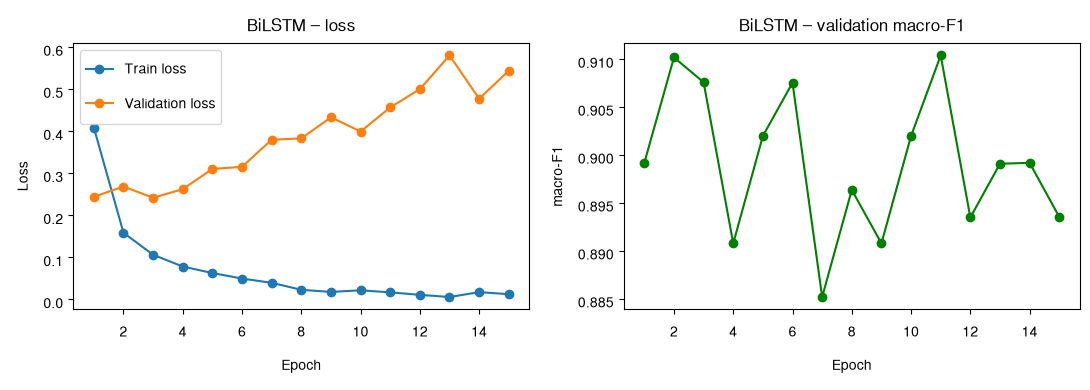

In [19]:
def plot_history(history, title, filename):
    epoch_numbers = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    ax1.plot(epoch_numbers, history["train_loss"], marker='o', label='Train loss')
    ax1.plot(epoch_numbers, history["val_loss"], marker='o', label='Validation loss')
    ax1.set_title(title + " – loss")
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax2.plot(epoch_numbers, history["val_macro_f1"], marker='o', color="green")
    ax2.set_title(title + " – validation macro-F1")
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('macro-F1')
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()

plot_history(history, "BiLSTM", "results/figures/03_training_history.png")

- The training loss keeps going down (0.408 → 0.012), but the **validation loss is lowest at epoch 3** (0.241) and then
  rises to 0.543: the model starts to **overfit** after a few epochs, like in the professor's notebook.
- Validation macro-F1 moves between 0.885 and 0.910; the best epoch is **11 (0.910)**, and its weights are restored.
- Training is fast on the GPU: under a minute for 15 epochs in all our runs (the exact time is printed above; it depends on the GPU and the laptop's power mode).

### 10. Model Evaluation (Test Sets)

With the best weights restored, we use the two test sets **once**.

=== test_translated (358 reviews) ===
              precision    recall  f1-score   support

    negative      0.941     0.894     0.917       179
    positive      0.899     0.944     0.921       179

    accuracy                          0.919       358
   macro avg      0.920     0.919     0.919       358
weighted avg      0.920     0.919     0.919       358



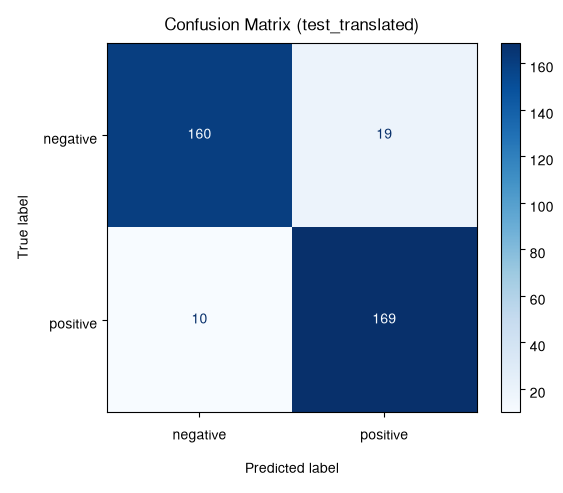

In [20]:
def get_predictions(model, loader):
    model.eval()
    predictions, labels, probabilities = [], [], []
    with torch.no_grad():
        for batch in loader:
            scores = model(batch["input_ids"].to(device))
            probs = torch.softmax(scores, dim=1)          # 2 scores → 2 probabilities
            predictions.extend(probs.argmax(dim=1).tolist())
            probabilities.extend(probs.tolist())
            labels.extend(batch["label"].tolist())
    return np.array(predictions), np.array(labels), np.array(probabilities)

def evaluate_test_set(loader, name):
    y_pred, y_true, probs = get_predictions(model, loader)
    print(f"=== {name} ({len(y_true)} reviews) ===")
    print(classification_report(y_true, y_pred, target_names=label_names, digits=3))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=label_names, cmap='Blues')
    plt.title(f"Confusion Matrix ({name})")
    plt.savefig(f"results/figures/03_confusion_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    return y_pred, probs

y_pred_translated, probs_translated = evaluate_test_set(test_translated_loader, "test_translated")

#### test_native: reviews written in Khmer (gold labels)

=== test_native (214 reviews) ===
              precision    recall  f1-score   support

    negative      0.974     0.659     0.786       170
    positive      0.414     0.932     0.573        44

    accuracy                          0.715       214
   macro avg      0.694     0.795     0.680       214
weighted avg      0.859     0.715     0.742       214



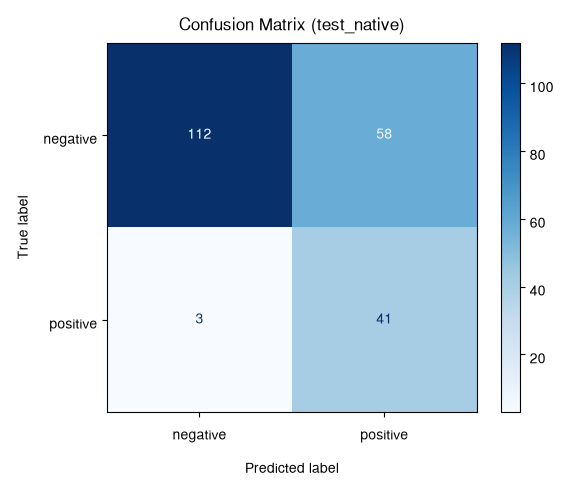

In [21]:
if LABEL_SOURCE == "silver":
    print("⚠ PROVISIONAL: test_native uses silver (AI) labels.\n")
y_pred_native, probs_native = evaluate_test_set(test_native_loader, "test_native")

#### Pure Khmer vs. code-switched (inside test_native)

In [22]:
def macro_f1_by_group(data, y_pred):
    scores = {}
    for group in ["pure_khmer", "code_switched"]:
        mask = (data["language_group"] == group).values
        scores[group] = f1_score(data["label_id"].values[mask], y_pred[mask], average="macro",
                                 labels=[0, 1], zero_division=0)
        print(f"{group:14s}: {mask.sum():3d} reviews | macro-F1 = {scores[group]:.3f}")
    return scores

group_scores = macro_f1_by_group(test_native, y_pred_native)

pure_khmer    : 193 reviews | macro-F1 = 0.708
code_switched :  21 reviews | macro-F1 = 0.430


#### Why is test_native harder? Unknown words

The vocabulary was built from the **translated** training reviews. How many words of each set are **not** in it (→ `<unk>`)?

In [23]:
for name, data in [("val", val), ("test_translated", test_translated), ("test_native", test_native)]:
    words = [word for tokens in data["token_list"] for word in tokens]
    unknown = sum(word not in word2idx for word in words)
    print(f"{name:16s}: {unknown / len(words):.1%} of the words are unknown (<unk>)")

val             : 2.2% of the words are unknown (<unk>)
test_translated : 2.0% of the words are unknown (<unk>)
test_native     : 20.8% of the words are unknown (<unk>)


- **test_translated: macro-F1 0.919** (accuracy 91.9%), lower than TF-IDF (0.964).
- **test_native: macro-F1 0.680** (accuracy 71.5%, gold labels), much lower than TF-IDF (0.851): only **65.9% of the
  real Khmer complaints are recognized** (negative recall 0.659); the others are predicted as positive.
- The reason is visible above: **20.8% of the words in real Khmer reviews are unknown** to the model (`<unk>`), against
  only about 2% in the translated sets. The vocabulary (1,507 words) comes from the translations, which use more formal,
  repetitive Khmer. Real reviews use informal spellings and words the BiLSTM has never seen, and an `<unk>` word carries
  no meaning. TF-IDF used **character** pieces as well, which still work for unknown words.
- pure_khmer 0.708 vs. code_switched 0.430 (only 21 reviews; English words are mostly `<unk>` here).

### 11. Predict New Reviews

The same 5 Khmer examples as in notebook 02:

| # | Meaning | Expected |
|---|---|---|
| 1 | very good service, friendly driver | positive |
| 2 | the driver doesn't really respect passengers (**negation**) | negative |
| 3 | the bus left two hours late and the AC was not cold | negative |
| 4 | thank you very much, even though the bus was two hours late (**indirect complaint**) | negative |
| 5 | not bad, a comfortable trip (**negation → positive**) | positive |

In [24]:
def predict(text):
    tokens = preprocess_text(text)
    input_ids = encode({"tokens": " ".join(tokens)})["input_ids"]

    model.eval()
    with torch.no_grad():
        scores = model(torch.tensor([input_ids]).to(device))
        probs = torch.softmax(scores, dim=1)[0]   # 2 scores → 2 probabilities

    print(f"\n{text}")
    for name, prob in sorted(zip(label_names, probs.tolist()), key=lambda x: x[1], reverse=True):
        print(f"  {name:8s}: {prob:.3f}")

NEW_REVIEWS = [
    "សេវាកម្មល្អណាស់ អ្នកបើកបររួសរាយរាក់ទាក់",
    "អ្នកបើកបរមិនសូវគោរពអ្នកដំណើរទេ",
    "ឡានចេញយឺតពីរម៉ោង ហើយម៉ាស៊ីនត្រជាក់មិនត្រជាក់",
    "សូមអរគុណច្រើន ទោះបីឡានយឺតពីរម៉ោងក៏ដោយ",
    "មិនអាក្រក់ទេ ធ្វើដំណើរបានស្រួល",
]
for review in NEW_REVIEWS:
    predict(review)

| 2026-11-25 11:51:22,158 | INFO | khmer-nltk | Loaded model from .venv\Lib\site-packages\khmernltk\word_tokenize\sklearn_crf_ner_10000.sav |



សេវាកម្មល្អណាស់ អ្នកបើកបររួសរាយរាក់ទាក់


  positive: 1.000
  negative: 0.000

អ្នកបើកបរមិនសូវគោរពអ្នកដំណើរទេ
  negative: 1.000
  positive: 0.000

ឡានចេញយឺតពីរម៉ោង ហើយម៉ាស៊ីនត្រជាក់មិនត្រជាក់
  negative: 0.997
  positive: 0.003

សូមអរគុណច្រើន ទោះបីឡានយឺតពីរម៉ោងក៏ដោយ
  positive: 1.000
  negative: 0.000

មិនអាក្រក់ទេ ធ្វើដំណើរបានស្រួល
  positive: 0.949
  negative: 0.051


- Examples 1, 2, 3 and 5 are correct, including both negation examples (2: មិន … ទេ, 5: "not bad").
- Example 4, the **indirect complaint**, is wrong again and even very confident (**positive 1.000**). The BiLSTM reads
  the words in order, but it learned from only 2,858 reviews and never learned that ទោះបី … ក៏ដោយ ("even though") turns
  "thank you" into a complaint.

### 12. Small Experiment: Frozen vs. Fine-tuned Embeddings

Our model **fine-tunes** the fastText vectors (`freeze=False`): the word vectors change during training.
What if we keep them **frozen** (`freeze=True`, like the professor's GloVe model)?
Same data, same seed, same 15 epochs; we compare the **best validation macro-F1** only (no test set).

In [25]:
torch.manual_seed(SEED)
frozen_model = BiLSTMClassifier(embedding_matrix, num_classes=len(label_names), freeze=True).to(device)
optimizer_frozen = torch.optim.Adam(frozen_model.parameters(), lr=0.001)

print("Frozen embeddings:")
frozen_trainable = count_parameters(frozen_model)
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, generator=torch.Generator().manual_seed(SEED))
frozen_history, frozen_best_f1, frozen_best_epoch = train_model(frozen_model, optimizer_frozen, epochs)

Frozen embeddings:
Trainable weights: 456,898
Frozen weights   : 452,100


Epoch  1 | train loss 0.5601 | val loss 0.3742 | val acc 0.849 | val macro-F1 0.849


Epoch  2 | train loss 0.3375 | val loss 0.4017 | val acc 0.838 | val macro-F1 0.836


Epoch  3 | train loss 0.2979 | val loss 0.2856 | val acc 0.880 | val macro-F1 0.879


Epoch  4 | train loss 0.2670 | val loss 0.2995 | val acc 0.877 | val macro-F1 0.876


Epoch  5 | train loss 0.2505 | val loss 0.3028 | val acc 0.868 | val macro-F1 0.868


... (6 outputs left out)

Epoch 12 | train loss 0.1574 | val loss 0.2201 | val acc 0.908 | val macro-F1 0.907


Epoch 13 | train loss 0.1533 | val loss 0.2146 | val acc 0.910 | val macro-F1 0.910


Epoch 14 | train loss 0.1373 | val loss 0.2007 | val acc 0.910 | val macro-F1 0.910


Epoch 15 | train loss 0.1305 | val loss 0.2053 | val acc 0.910 | val macro-F1 0.910

Best epoch: 14 (validation macro-F1 0.910) → these weights are restored


#### Result of the experiment

In [26]:
experiment = pd.DataFrame({
    "embeddings": ["fine-tuned (freeze=False)", "frozen (freeze=True)"],
    "trainable weights": [n_parameters, frozen_trainable],
    "best epoch": [best_epoch, frozen_best_epoch],
    "best validation macro-F1": [round(best_val_f1, 3), round(frozen_best_f1, 3)],
})
print(experiment.to_string(index=False))

               embeddings  trainable weights  best epoch  best validation macro-F1
fine-tuned (freeze=False)             908998          11                      0.91
     frozen (freeze=True)             456898          14                      0.91


- Both versions reach the **same best validation macro-F1 (0.910)**.
- Fine-tuning **doubles the trainable weights** (908,998 vs. 456,898) and the fine-tuned model overfits much faster
  (training loss 0.012 vs. 0.131 at epoch 15; its best epoch is 11, the frozen model's is 14).
- So with our small dataset, fine-tuning the embeddings does not help. The fastText vectors are also not
  sentiment-aware: **ល្អ** ("good") is *more* similar to **អាក្រក់** ("bad", 0.551) than to **អស្ចារ្យ** ("amazing", 0.384),
  because opposite words appear in the same kind of sentences.

### 13. Save Predictions and Metrics

| File | Content |
|---|---|
| `results/predictions/bilstm_{test set}.csv` | one row per review: true label, predicted label, probabilities |
| `results/metrics/bilstm.json` | accuracy and macro-F1 per test set, best validation macro-F1, settings |

In [27]:
def save_predictions(data, y_pred, probs, test_set):
    out = pd.DataFrame({
        "row_id": data["row_id"], "text_km": data["text_km"],
        "true_label": data["label"], "pred_label": [label_names[i] for i in y_pred],
        "prob_negative": probs[:, 0].round(4), "prob_positive": probs[:, 1].round(4),
    })
    out.to_csv(f"results/predictions/bilstm_{test_set}.csv", index=False, encoding="utf-8")

save_predictions(test_translated, y_pred_translated, probs_translated, "test_translated")
save_predictions(test_native, y_pred_native, probs_native, "test_native")

metrics = {
    "model": "bilstm",
    "model_type": "Neural network",
    "model_name": "BiLSTM + fastText",
    "input_features": "khmer-nltk words → fastText Khmer embeddings (fine-tuned)" if USE_FASTTEXT
                      else "khmer-nltk words → random embeddings",
    "uses_word_order": "yes",
    "uses_context": "yes (reads the review in both directions)",
    "trainable_parameters": int(n_parameters),
    "best_val_macro_f1": round(float(best_val_f1), 4),
    "settings": {"max_len": max_len, "vocab_size": vocab_size, "embedding": "fastText cc.km.300" if USE_FASTTEXT else "random",
                 "freeze_embeddings": False, "hidden_size": 128, "dropout": 0.3, "batch_size": batch_size,
                 "lr": 0.001, "epochs": epochs, "best_epoch": best_epoch, "device": device,
                 "frozen_embeddings_best_val_macro_f1": round(float(frozen_best_f1), 4)},
    "training_time_sec": round(training_time, 2),
    "test_translated": {"accuracy": round(accuracy_score(test_translated["label_id"], y_pred_translated), 4),
                        "macro_f1": round(f1_score(test_translated["label_id"], y_pred_translated, average="macro"), 4)},
    "test_native": {"accuracy": round(accuracy_score(test_native["label_id"], y_pred_native), 4),
                    "macro_f1": round(f1_score(test_native["label_id"], y_pred_native, average="macro"), 4),
                    "pure_khmer_macro_f1": round(group_scores["pure_khmer"], 4),
                    "code_switched_macro_f1": round(group_scores["code_switched"], 4)},
    "test_native_label_source": LABEL_SOURCE,
}
with open("results/metrics/bilstm.json", "w") as f:
    json.dump(metrics, f, indent=2)
print(json.dumps(metrics, indent=2))

{
  "model": "bilstm",
  "model_type": "Neural network",
  "model_name": "BiLSTM + fastText",
  "input_features": "khmer-nltk words \u2192 fastText Khmer embeddings (fine-tuned)",
  "uses_word_order": "yes",
  "uses_context": "yes (reads the review in both directions)",
  "trainable_parameters": 908998,
  "best_val_macro_f1": 0.9104,
  "settings": {
    "max_len": 47,
    "vocab_size": 1507,
    "embedding": "fastText cc.km.300",
    "freeze_embeddings": false,
    "hidden_size": 128,
    "dropout": 0.3,
    "batch_size": 32,
    "lr": 0.001,
    "epochs": 15,
    "best_epoch": 11,
    "device": "cuda",
    "frozen_embeddings_best_val_macro_f1": 0.9103
  },
  "training_time_sec": 3.75,
  "test_translated": {
    "accuracy": 0.919,
    "macro_f1": 0.9189
  },
  "test_native": {
    "accuracy": 0.715,
    "macro_f1": 0.6797,
    "pure_khmer_macro_f1": 0.7078,
    "code_switched_macro_f1": 0.4296
  },
  "test_native_label_source": "gold"
}


### 14. Observations

- **Results** (BiLSTM + fastText, best epoch 11 of 15, 908,998 trainable weights, under a minute on the GPU):

| Test set | Accuracy | Macro-F1 | TF-IDF (notebook 02) |
|---|---|---|---|
| test_translated | 0.919 | **0.919** | 0.964 |
| test_native (gold labels) | 0.715 | **0.680** | 0.851 |

- **The neural network is worse than the TF-IDF baseline**, especially on real Khmer text (translation gap −0.24 macro-F1).
- Main reasons, all visible in this notebook:
  - **small training set** (2,858 reviews) for 908,998 weights → overfitting after about 3 epochs;
  - **word-level vocabulary from translations** → 20.8% unknown words on real Khmer reviews (vs. 2% on translations);
  - pretrained fastText vectors are general-purpose, not sentiment-aware (ល្អ "good" ≈ អាក្រក់ "bad").
- Reading word order handles **negation** in our examples, but not the **indirect complaint**.
- Lesson: a more complex model is **not automatically better**; it needs more data or better pretrained knowledge.
  Notebook 04 tests the second idea: XLM-R was **pretrained on a lot of Khmer text** and uses **subword pieces**,
  so it has (almost) no unknown words.
- Note: GPU results can differ very slightly on another GPU, even with the same seed.